# 17 — Extra: Amostragem e Viés

Todo o livro partiu de uma suposição silenciosa: a amostra é **representativa** da população (sorteada ao acaso, com valores independentes). O erro padrão, os intervalos de confiança e os testes medem só o **erro aleatório**, aquele que diminui com mais dados.

Mas existe um erro muito mais traiçoeiro: o **viés de amostragem**, quando a forma de coletar os dados favorece sistematicamente alguns casos. Ele **não diminui** com mais dados, e nenhuma fórmula do livro o detecta.

Neste notebook extra vamos:
- Comparar **amostragem aleatória simples** e **amostragem estratificada**
- Entender o `stratify=y` do `train_test_split` usado no ML-01 e no ML-02
- Ver o **viés de seleção** em ação, e por que a LGN não o corrige
- Conhecer o **viés de sobrevivência**
- Corrigir uma amostra enviesada com **pesos** (ponderação pelo inverso da probabilidade)

## 1. Importando bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

## 2. Uma população simulada

Vamos criar uma "cidade" com 100.000 pessoas em quatro regiões de tamanhos e rendas diferentes. Como a população é simulada, conhecemos a **resposta verdadeira** e podemos medir o erro de cada forma de amostrar.

In [2]:
regioes = pd.DataFrame({
    "região": ["Centro", "Norte", "Sul", "Periferia"],
    "proporção": [0.10, 0.25, 0.25, 0.40],
    "renda mediana": [9_000, 4_500, 4_000, 2_200],
})
n_pop = 100_000
# rng.choice com p=... sorteia a região de cada pessoa com as proporções dadas.
regiao = rng.choice(regioes["região"], size=n_pop, p=regioes["proporção"])
mediana = regioes.set_index("região")["renda mediana"]
# Renda log-normal (notebook 08) em torno da mediana de cada região.
renda = rng.lognormal(mean=np.log(mediana[regiao].to_numpy()), sigma=0.5)
populacao = pd.DataFrame({"região": regiao, "renda": renda})

media_real = populacao["renda"].mean()
print(f"Renda média VERDADEIRA da cidade: R$ {media_real:,.0f}".replace(",", "."))
populacao.groupby("região")["renda"].agg(["count", "mean", "std"]).round(0)

Renda média VERDADEIRA da cidade: R$ 4.429


,count,mean,std
região,,,
Centro,9916,10253.0,5563.0
Norte,24941,5128.0,2753.0
Periferia,40156,2496.0,1332.0
Sul,24987,4528.0,2461.0


## 🎓 Conceito: amostragem aleatória simples × estratificada

- **Aleatória simples:** todas as pessoas têm a mesma chance de entrar na amostra. Por azar, uma amostra pode ter gente demais de uma região e de menos de outra.
- **Estratificada:** dividimos a população em **estratos** (as regiões) e sorteamos, dentro de cada um, uma quantidade **proporcional** ao seu tamanho. A composição da amostra fica sempre igual à da população, eliminando uma fonte de variação.

As duas são **não viesadas**, mas a estratificada costuma ter **menor variância**, especialmente quando os estratos são muito diferentes entre si.

Média verdadeira: 4.429
Simples:       média das estimativas = 4.424   erro padrão = 241
Estratificada: média das estimativas = 4.437   erro padrão = 184


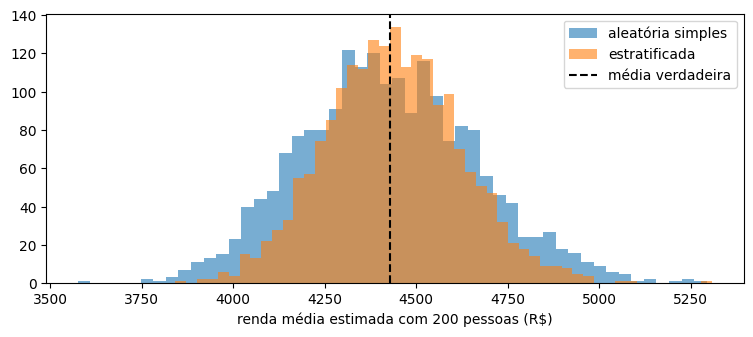

In [3]:
def amostra_simples(n):
    return populacao["renda"].sample(n, random_state=rng.integers(1_000_000)).mean()


def amostra_estratificada(n):
    # Para cada região, sorteia uma quantidade proporcional ao tamanho dela e junta tudo.
    partes = [grupo["renda"].sample(round(n * len(grupo) / n_pop), random_state=rng.integers(1_000_000))
              for _, grupo in populacao.groupby("região")]
    return pd.concat(partes).mean()


n = 200
simples = np.array([amostra_simples(n) for _ in range(2_000)])
estratificada = np.array([amostra_estratificada(n) for _ in range(2_000)])

print(f"Média verdadeira: {media_real:,.0f}".replace(",", "."))
print(f"Simples:       média das estimativas = {simples.mean():,.0f}   erro padrão = {simples.std():,.0f}".replace(",", "."))
print(f"Estratificada: média das estimativas = {estratificada.mean():,.0f}   erro padrão = {estratificada.std():,.0f}".replace(",", "."))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(simples, bins=50, alpha=0.6, label="aleatória simples")
ax.hist(estratificada, bins=50, alpha=0.6, label="estratificada")
ax.axvline(media_real, color="black", linestyle="--", label="média verdadeira")
ax.set_xlabel("renda média estimada com 200 pessoas (R$)")
ax.legend()
plt.show()

**Conclusão:** as duas formas de amostrar acertam **em média** (4.424 e 4.437, contra a média verdadeira de **R\$ 4.429**): nenhuma tem viés. Mas a estratificada erra **menos** de amostra para amostra: erro padrão de **R\$ 184**, contra **R\$ 241** da simples, cerca de 24% a menos. No gráfico, o histograma da estratificada é mais estreito.

O ganho vem de as regiões serem muito diferentes (renda média de R\$ 10.253 no Centro e R\$ 2.496 na Periferia). Na amostra simples, parte do erro vem só de sortear, por azar, gente demais do Centro ou da Periferia; a estratificação elimina essa fonte de variação. Ter os mesmos 200 entrevistados, só que mais bem distribuídos, equivale a ter uma amostra simples bem maior.

## 3. O `stratify=y` do ML

No ML-02, separamos treino e teste com `stratify=y`. A razão é a mesma: com uma classe **rara**, uma separação puramente aleatória pode deixar o conjunto de teste com proporções bem diferentes do treino, e a métrica de teste fica mais "sortuda" ou "azarada".

In [4]:
# Um alvo raro: 3% de positivos em 2.000 exemplos.
y = (rng.random(2_000) < 0.03).astype(int)
X = np.arange(2_000).reshape(-1, 1)   # os atributos não importam aqui

proporcoes = {"sem stratify": [], "com stratify": []}
for semente in range(1_000):
    _, _, _, y_teste = train_test_split(X, y, test_size=0.2, random_state=semente)
    proporcoes["sem stratify"].append(y_teste.mean())
    _, _, _, y_teste = train_test_split(X, y, test_size=0.2, random_state=semente, stratify=y)
    proporcoes["com stratify"].append(y_teste.mean())

print(f"Proporção real de positivos: {y.mean():.2%}")
for nome, valores in proporcoes.items():
    valores = np.array(valores)
    print(f"{nome:>13}: proporção no teste varia de {valores.min():.2%} a {valores.max():.2%} (desvio {valores.std():.2%})")

Proporção real de positivos: 2.25%
 sem stratify: proporção no teste varia de 0.50% a 4.50% (desvio 0.64%)
 com stratify: proporção no teste varia de 2.25% a 2.25% (desvio 0.00%)


**Conclusão:** (Por acaso, a simulação gerou **2,25%** de positivos, e não exatamente 3%.) Sem `stratify`, a proporção de positivos no conjunto de teste de 400 exemplos variou de **0,50% a 4,50%** entre as 1.000 separações: num teste com 0,5% de positivos (só 2 exemplos!), qualquer métrica da classe rara seria pouco confiável. Com `stratify=y`, **todas** as separações tiveram exatamente **2,25%**, a mesma proporção do conjunto completo.

É a amostragem estratificada aplicada ao alvo, e por isso ela é a escolha padrão na classificação, especialmente com classes desbalanceadas.

## 🎓 Conceito: viés de seleção

O **viés de seleção** acontece quando a chance de uma pessoa entrar na amostra **depende** da variável que estamos medindo (ou de algo relacionado a ela).

Exemplo: uma pesquisa de renda feita **por um aplicativo de celular caro**. Pessoas de renda mais alta têm mais chance de ter o aplicativo, então a amostra vai superestimar a renda. E o pior: **aumentar a amostra não ajuda**. A LGN garante que a média converge... para a média **da população que responde**, não para a da cidade.

O caso histórico mais famoso: em 1936, a revista *Literary Digest* consultou **2,4 milhões** de pessoas (listas de telefones e de donos de carros, numa época em que só os mais ricos os tinham) e previu a vitória de Landon sobre Roosevelt. Roosevelt venceu com folga. Uma pesquisa com alguns milhares de pessoas bem escolhidas acertou.

In [5]:
# Probabilidade de responder pelo aplicativo: cresce com a renda (uma curva logística).
p_responder = 1 / (1 + np.exp(-(np.log(populacao["renda"]) - np.log(6_000)) * 2))
responde = rng.random(n_pop) < p_responder

print(f"Proporção que responde: {responde.mean():.1%}")
for n_amostra in [100, 1_000, 10_000]:
    respondentes = populacao.loc[responde, "renda"]
    estimativa = respondentes.sample(n_amostra, random_state=1).mean()
    print(f"  {n_amostra:>6} respostas: renda média estimada = R$ {estimativa:,.0f}".replace(",", "."))
print(f"Média de TODOS os respondentes:   R$ {populacao.loc[responde, 'renda'].mean():,.0f}".replace(",", "."))
print(f"Média verdadeira da cidade:       R$ {media_real:,.0f}".replace(",", "."))

Proporção que responde: 30.8%
     100 respostas: renda média estimada = R$ 7.409
    1000 respostas: renda média estimada = R$ 6.803
   10000 respostas: renda média estimada = R$ 6.806
Média de TODOS os respondentes:   R$ 6.833
Média verdadeira da cidade:       R$ 4.429


**Conclusão:** só **30,8%** da cidade responde, e a amostra é dominada por quem tem renda alta. A estimativa fica em torno de **R\$ 6.800**, cerca de **54% acima** da média verdadeira (R\$ 4.429), e não melhora com mais respostas: com 1.000 respostas, R\$ 6.803; com 10.000, R\$ 6.806. Ela converge, como manda a LGN, mas para a média dos **respondentes** (R\$ 6.833).

Um intervalo de confiança calculado com essas 10.000 respostas seria estreitíssimo e ficaria **inteiro** longe da resposta certa. A precisão é alta; a exatidão é péssima. Mais dados enviesados só dão mais **confiança** num número errado.

## 🎓 Conceito: corrigindo com pesos

Se soubermos (ou conseguirmos estimar) a **probabilidade de cada pessoa ter sido incluída**, podemos corrigir o viés dando a cada resposta um **peso igual ao inverso dessa probabilidade**: quem tinha pouca chance de responder "representa" muitas pessoas parecidas que não responderam.

Esse é o **estimador de Horvitz-Thompson**, ou ponderação pelo inverso da probabilidade (IPW). Ele é a base dos pesos usados nas pesquisas oficiais (como as do IBGE) e da **correção de mudança de distribuição** em ML.

Na prática, não conhecemos a probabilidade exata de cada pessoa, mas costumamos conhecer a **composição da população** por grupos (pelo censo, por exemplo). Uma versão simples é a **pós-estratificação**: calcular a média de cada região na amostra e combiná-las com os pesos **verdadeiros** das regiões.

In [6]:
amostra = populacao[responde].sample(2_000, random_state=1).copy()
amostra["p_responder"] = p_responder[amostra.index]

simples = amostra["renda"].mean()
# IPW: média ponderada com pesos 1 / p. np.average aceita um vetor de pesos.
ipw = np.average(amostra["renda"], weights=1 / amostra["p_responder"])
# Pós-estratificação: média por região na amostra, ponderada pela proporção real de cada região.
medias_regiao = amostra.groupby("região")["renda"].mean()
pesos_reais = populacao["região"].value_counts(normalize=True)
pos_estrat = np.sum(medias_regiao * pesos_reais[medias_regiao.index])

print("Composição da amostra × população:")
print(pd.DataFrame({"amostra": amostra["região"].value_counts(normalize=True), "população": pesos_reais}).round(3), "\n")
for nome, valor in [("média simples (enviesada)", simples), ("IPW (pesos 1/p)", ipw),
                    ("pós-estratificação por região", pos_estrat), ("VERDADEIRA", media_real)]:
    print(f"{nome:>30}: R$ {valor:,.0f}".replace(",", "."))

Composição da amostra × população:
           amostra  população
região                       
Centro       0.234      0.099
Norte        0.308      0.249
Periferia    0.192      0.402
Sul          0.266      0.250 

     média simples (enviesada): R$ 6.919
               IPW (pesos 1/p): R$ 4.464
 pós-estratificação por região: R$ 5.627
                    VERDADEIRA: R$ 4.429


**Conclusão:** a amostra tem **23,4%** de pessoas do Centro (contra 9,9% na população) e só **19,2%** da Periferia (contra 40,2%). As correções funcionam de formas diferentes:
- A **média simples** (R\$ 6.919) erra feio.
- O **IPW**, que usa a probabilidade exata de cada pessoa responder, chega a **R\$ 4.464**, muito perto da verdade (R\$ 4.429).
- A **pós-estratificação** corrige a composição das regiões, mas só **parcialmente** a média (**R\$ 5.627**): dentro de cada região, quem responde continua sendo quem tem renda mais alta, e essa parte do viés os pesos por região não enxergam.

A lição honesta: os pesos só corrigem o viés que eles **conseguem descrever**. Se a seleção depende de algo que não está nos pesos, sobra viés. Na prática, as pesquisas usam o maior número possível de variáveis (região, idade, escolaridade...) para construir os pesos.

## 🎓 Conceito: viés de sobrevivência

Um caso especial de viés de seleção: olhamos só para quem **"sobreviveu"** a algum filtro e tiramos conclusões sobre todos.

O exemplo clássico vem da Segunda Guerra Mundial: os militares analisavam os aviões que **voltavam** das missões e queriam reforçar as partes com mais buracos de bala. O estatístico Abraham Wald percebeu o erro: os aviões atingidos nas **outras** partes (como os motores) **não voltavam**. Era justamente onde **não** havia buracos que o reforço era necessário.

Vamos simular algo parecido com **fundos de investimento**: só os fundos que não fecharam aparecem no ranking de hoje.

In [7]:
# 5.000 fundos ao longo de 10 anos. O retorno anual de cada um é puro acaso: média 0%, desvio 15%.
n_fundos, anos = 5_000, 10
retornos = rng.normal(0.0, 0.15, size=(n_fundos, anos))
patrimonio = np.cumprod(1 + retornos, axis=1)          # cumprod: produto acumulado (juros compostos)
# Um fundo fecha se, em algum ano, acumular perda maior que 30%.
fechou = (patrimonio < 0.7).any(axis=1)
retorno_anual = patrimonio[:, -1] ** (1 / anos) - 1      # retorno médio anual composto

print(f"Fundos que fecharam: {fechou.mean():.1%}")
print(f"Retorno anual médio de TODOS os fundos:          {retorno_anual.mean():+.2%}")
print(f"Retorno anual médio dos fundos 'sobreviventes':  {retorno_anual[~fechou].mean():+.2%}")

Fundos que fecharam: 44.1%
Retorno anual médio de TODOS os fundos:          -1.05%
Retorno anual médio dos fundos 'sobreviventes':  +2.06%


**Conclusão:** os retornos foram gerados **sem nenhuma habilidade**: todos os fundos são puro acaso, com retorno médio próximo de zero (**−1,05%** ao ano, considerando todos). Mas **44,1%** dos fundos fecharam ao longo dos 10 anos, e os que sobraram mostram retorno médio de **+2,06%** ao ano. Quem olhasse só o ranking atual concluiria que "fundos rendem cerca de 2% ao ano", quando a média real é negativa.

O filtro "sobreviveu" escolheu justamente os que tiveram sorte. É o mesmo raciocínio dos aviões de Wald, e aparece em toda parte: empresas de sucesso estudadas em livros de negócios, apps que "deram certo", ou modelos de crédito treinados só com os clientes que **foram aprovados** no passado.

## 4. Resumo

| Erro | Diminui com mais dados? | Detectado pelos ICs e testes? | Como combater |
|---|---|---|---|
| **Aleatório** (amostragem) | ✅ sim, como $1/\sqrt{n}$ | ✅ sim | mais dados, estratificação |
| **Viés de seleção** | ❌ não | ❌ não | desenho da coleta, pesos (IPW), pós-estratificação |
| **Viés de sobrevivência** | ❌ não | ❌ não | incluir os casos que "sumiram" |

**Conceitos que você aprendeu**
- **Amostragem aleatória simples** e **estratificada**, e por que o `stratify=y` estabiliza o conjunto de teste.
- **Viés de seleção**: mais dados convergem para a resposta **errada**.
- Correção com **pesos** (IPW) e **pós-estratificação**.
- **Viés de sobrevivência**.

🔗 **Ponte para o ML:** um modelo aprende a população **dos dados de treino**. Se eles foram coletados de forma enviesada (só clientes que aceitaram uma oferta, só pacientes de um hospital, só imagens de um tipo de câmera), o modelo pode funcionar bem no teste (que tem o mesmo viés) e falhar no mundo real. A discussão de **justiça** do ML-02 é, em boa parte, uma discussão sobre de onde vieram os dados.

**Python novo:** `rng.choice(..., p=...)`, `.sample(n, random_state=...)`, `train_test_split(..., stratify=y)`, `np.average(..., weights=...)`, `np.cumprod`.